SKAIDRĪTES SKUDRIŅAS 7.POSMS

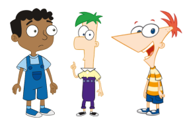

In [57]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


In [ ]:
# Parametri
r, mk, L, g = 0.4, 80.0, 1.0, 9.81
mT = 84.0                     

In [ ]:
# Regulatora koeficienti
Kp = 480
Kd = 31

def robots(t, y):
    x, xd, th, thd = y
    tau = Kp * th + Kd * thd                       # PD regulators

    A = [[mT,              mk * L * np.cos(th)],
         [mk * L * np.cos(th), mk * L**2      ]]
    b = [tau / r + mk * L * thd**2 * np.sin(th),
         mk * g * L * np.sin(th) - tau]

    xdd, thdd = np.linalg.solve(A, b)
    return [xd, xdd, thd, thdd]

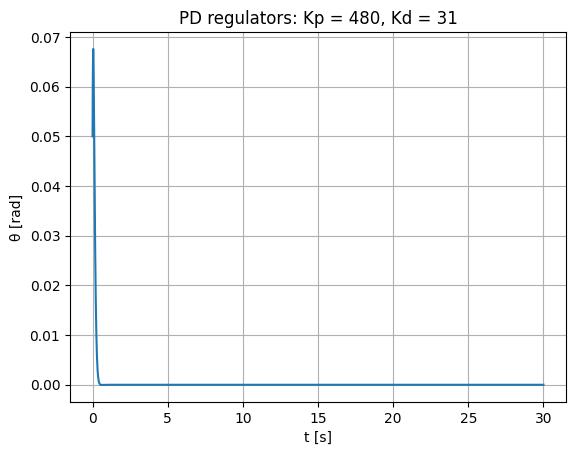

In [60]:
# Simulācija: sākumā sasvēries par 0.05 rad
sol = solve_ivp(robots, (0, 30), [0, 0, 0.05, 1], max_step=0.01)

# Grafiks
plt.plot(sol.t, sol.y[2])
plt.xlabel("t [s]")
plt.ylabel("θ [rad]")
plt.title(f"PD regulators: Kp = {Kp}, Kd = {Kd}")
plt.grid()
plt.show()